# Análisis de mediciones SDR — potencia y ancho de banda
Cumple el punto *Análisis 2* de la guía: **medir potencia y ancho de banda transmitido y recibido**.
Entrada: captura IQ (`complex64`, formato `.cfile` de GNU Radio *File Sink*) del lado TX (HackRF) y/o RX (RTL-SDR). Mientras no existan capturas reales, el cuaderno corre con una señal sintética para validar el método.

Convenciones: potencia en dBFS (referida a plena escala del ADC, no es dBm absoluta); la medición en dBm absolutos se hace con el **analizador de espectro / osciloscopio** y se anota en `data/mediciones/`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

FIG_DIR = "../figures" if os.path.isdir("../figures") else None
def guardar(nombre):
    if FIG_DIR: plt.savefig(f"{FIG_DIR}/{nombre}.png", dpi=150, bbox_inches="tight")

In [2]:
def cargar_iq(ruta):
    """Lee una captura de GNU Radio (File Sink, complex64 intercalado I,Q)."""
    return np.fromfile(ruta, dtype=np.complex64)

def psd(iq, fs, nfft=4096):
    """Densidad espectral de potencia (Welch) centrada en 0 Hz. Devuelve f [Hz] y P [dB]."""
    f, p = signal.welch(iq, fs=fs, nperseg=nfft, return_onesided=False, scaling='density')
    f, p = np.fft.fftshift(f), np.fft.fftshift(p)
    return f, 10*np.log10(p + 1e-20)

def potencia_dbfs(iq):
    """Potencia media de la captura en dBFS (|x|^2 con plena escala = 1)."""
    return 10*np.log10(np.mean(np.abs(iq)**2) + 1e-20)

def ancho_banda_xdb(f, p_db, x=3.0):
    """Ancho de banda a -x dB respecto del pico del espectro suavizado."""
    from scipy.ndimage import uniform_filter1d
    ps = 10*np.log10(uniform_filter1d(10**(p_db/10), size=9, mode='nearest'))  # suavizado en lineal (no en dB)
    ok = f[ps >= ps.max() - x]
    return ok.max() - ok.min()

def ancho_banda_ocupado(iq, fs, fraccion=0.99, nfft=4096):
    """Ancho de banda que contiene `fraccion` de la potencia total (OBW)."""
    f, p = signal.welch(iq, fs=fs, nperseg=nfft, return_onesided=False)
    f, p = np.fft.fftshift(f), np.fft.fftshift(p)
    c = np.cumsum(p)/np.sum(p)
    return f[np.searchsorted(c, (1+fraccion)/2)] - f[np.searchsorted(c, (1-fraccion)/2)]

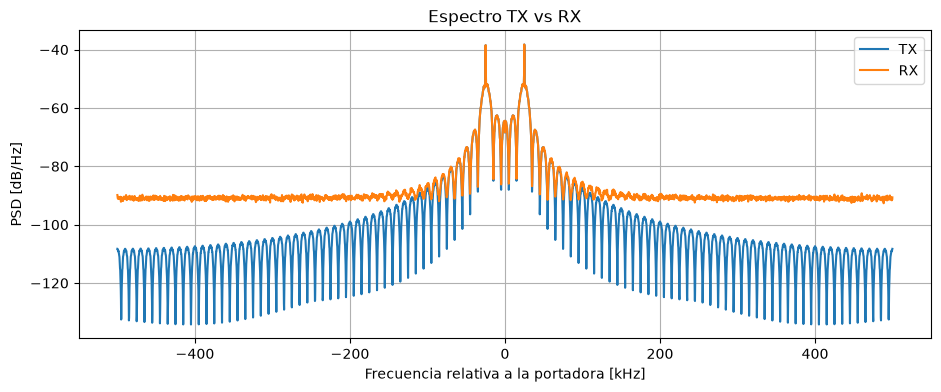

      P [dBFS]   BW -3dB [kHz]  BW -20dB [kHz]   OBW 99% [kHz]
TX       -6.02            52.0            65.4            73.2
RX       -6.01            52.0            65.4            78.6
Regla de Carson (referencia):  60.0 kHz


In [3]:
# --- Señal sintética de validación: 2-FSK complejo a 1 Msps, 10 kbaud, desviación ±25 kHz ---
rng = np.random.default_rng(1)
fs, baud, dev = 1_000_000, 10_000, 25_000
bits = rng.integers(0, 2, 2000)
sps = fs//baud
freq = np.repeat((2*bits-1)*dev, sps)                    # ±desviación por bit
fase = 2*np.pi*np.cumsum(freq)/fs                        # fase continua (CPFSK)
iq_tx = 0.5*np.exp(1j*fase)
iq_rx = iq_tx + 0.02*(rng.standard_normal(len(iq_tx)) + 1j*rng.standard_normal(len(iq_tx)))   # canal con ruido

# --- Para datos reales descomente: ---
# iq_tx = cargar_iq("../data/mediciones/tx.cfile"); iq_rx = cargar_iq("../data/mediciones/rx.cfile"); fs = ...  # Hz

filas = []
plt.figure(figsize=(11, 4))
for nombre, iq in [("TX", iq_tx), ("RX", iq_rx)]:
    f, p = psd(iq, fs)
    plt.plot(f/1e3, p, label=nombre)
    filas.append((nombre, potencia_dbfs(iq), ancho_banda_xdb(f, p, 3)/1e3, ancho_banda_xdb(f, p, 20)/1e3, ancho_banda_ocupado(iq, fs)/1e3))
plt.xlabel("Frecuencia relativa a la portadora [kHz]"); plt.ylabel("PSD [dB/Hz]"); plt.title("Espectro TX vs RX"); plt.grid(True); plt.legend()
guardar("sdr_01_espectro_tx_rx"); plt.show()

print(f"{'':4}{'P [dBFS]':>10}{'BW -3dB [kHz]':>16}{'BW -20dB [kHz]':>16}{'OBW 99% [kHz]':>16}")
for n, pw, b3, b20, obw in filas:
    print(f"{n:4}{pw:10.2f}{b3:16.1f}{b20:16.1f}{obw:16.1f}")
print("Regla de Carson (referencia): ", 2*(dev+baud/2)/1e3, "kHz")